# Standardization, uncertainties, and binning

In [1]:
%matplotlib inline
import os
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


180 51 [{'operation': 'standardize', 'offset': -0.012481826042682827, 'scale': 0.2190901460079897}, {'operation': 'bin', 'width': 0.2}]


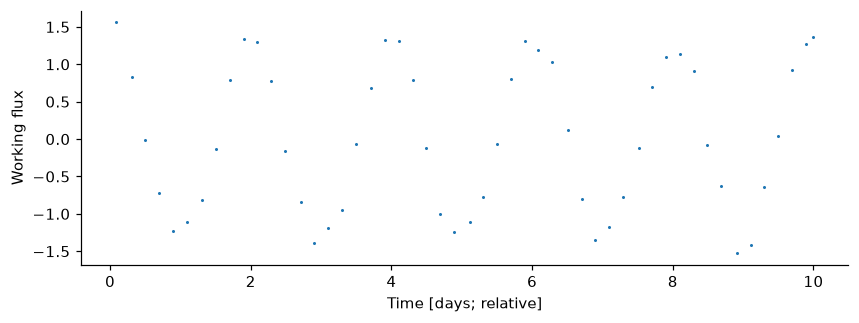

In [2]:
# Generate 180 reproducible observations with signal and noise.
lc = Nahiku.from_synthetic_noise(n_points=180, seed=1)

# Save an independent flux copy and its standard deviation for comparison.
original = lc.flux.copy()
scale = np.std(original)

# Center and scale working flux; divide uncertainties by the same standard deviation.
lc.standardize()

# Verify that uncertainties were scaled and original observations were preserved.
assert np.allclose(lc.flux_err, lc.original_flux_err/scale)
assert np.array_equal(lc.original_flux, original)

# Create a separate light curve using 0.2-day bins, leaving the parent unchanged.
binned = lc.bin(0.2)

# Inspect the sample counts and processing history, then plot the binned data.
print(len(lc.time), len(binned.time), binned.history)
binned.plot();

# Restore the parent to its original observations and clear derived analysis state.
lc.reset()

# Confirm that reset recovered the original flux exactly.
assert np.array_equal(lc.flux, original)


## Interpret the result

Binning assumes independent measurement errors and does not remove correlated noise. Metadata records the samples in each bin, and the parent object remains unchanged. Recompute fits and search results after transforming the data.

Consult the API reference for parameter and return-value details.